## Das künstliche Neuron - das Perzeptron

<figure>
    <img src="Bilder/Neuron_Hand-tuned2.svg" alt="Perceptron" width = 300>
    <figcaption>Aufbau einer Nervenzelle. (CC BY-SA 4.0, https://commons.wikimedia.org/w/index.php?curid=151245917)</figcaption>
</figure>

Ein Neuron ist die Grundbaueinheit des Nervensystems. Es dient dazu, Informationen aufzunehmen, zu verarbeiten und weiterzuleiten – elektrisch und chemisch.

Ein typisches Neuron besteht aus drei Hauptteilen:

Dendriten

* kurze, verzweigte Fortsätze
* nehmen Signale von anderen Zellen auf

Zellkörper

* enthält den Zellkern
* verarbeitet die eingehenden Signale

Axon

* langer Fortsatz
* leitet elektrische Signale (Aktionspotenziale) weiter
* endet an Synapsen, wo das Signal an andere Neuronen oder Muskeln übertragen wird

  <figure>
    <img src="Bilder/Perceptron-or-task.svg" alt="Perceptron" width = 300>
    <figcaption>Einfaches einlagiges Perceptron. (CC BY 3.0, https://commons.wikimedia.org/w/index.php?curid=28211506)</figcaption>
  </figure>

Das Perzeptron ist ein vereinfachtes künstliches neuronales Netz, das zuerst von Frank Rosenblatt 1957 vorgestellt wurde. Es besteht in der Grundversion aus einem einzelnen künstlichen Neuron mit anpassbaren Gewichtungen und einem Schwellenwert. 

Das biologische Neuron ist das Vorbild für das künstliche Neuron. Das künstliche Neuron besteht aus folgenden Bestandteilen:
Einem Eingangsvektor, der die Eingangsdaten enthält (auch Dendrit genannt), einem Gewichtungsvektor, der die Eingangsdaten wichtet und gewichtet weitergibt (Synapse) und einem Zellkörper, der das Resultat aus Dendrit und Synapse darstell. Damit verknüpft ist eine Entscheidungsfunktion y. Dabei wird eine Eins von der Entscheidungsfunktion weitergegeben, wenn das Resultat aus Dendrit und Synapse einen Schwellenwert überschreitet und eine Null, wenn das Resultat aus Dendrit und Synapse einen Schwellenwert unterschreitet.

$$\begin{pmatrix} x_1 \\ x_2 \\ .. \\ x_n \end{pmatrix} \cdot \begin{pmatrix} w_1 \\ w_2 \\ .. \\ w_n \end{pmatrix} = \sum_{i=1}^n x_i w_i$$

und für die Entscheidungsfunktion y gilt

$$y = \delta(\vec{x},\vec{w}) = \delta{\left(\sum_{i=1}^n x_i w_i\right)}$$

Mit Hilfe des einfachen Perzeptrons können Daten linear getrennt und somit klassifiziert werden. 

### Beispiel 1: 

Rettern Sie den kleinen Roboter vor dem Absturz. Dieser kleine Roboter fährt vor sich hin und führt nichts Böses im
Schilde. Doch die Umgebung ist ihm nicht wohlgesonnen, und große gefährliche Löcher meinen es nicht gut mit ihm. Glücklicherweise besitzt der Roboter zwei Hell-Dunkel-Sensoren, links und rechts vorn montiert, die die Bodenhelligkeit vor dem Roboter bestimmen können.

 <figure>
    <img src="Bilder/Roboter_Aufgabe.png" alt="Roboter" width = 300>
    <figcaption>Roboter mit zwei Sensoren</figcaption>
  </figure>

In [ ]:
#| code-fold: true
#| code-summary: "Lösung anzeigen"

# Mathematik
import numpy as np
# Plot
import matplotlib.pyplot as plt
# 3-dimensionaler Input = Bias-Neuron, Sensor links, Sensor rechts
# 4 Inputvektoren
X = np.array([[1,0,0],[1,0,1],[1,1,0],[1,1,1]])
# Die 4 gewünschten Ergebniswerte
y = np.array([0,0,0,1])

# Heaviside-Funktion
def heaviside( summe ):
    """Berechnung der Entscheidung zum Wert summe
    Input: summe
    Output: 1, falls summe >= 0,
    0 sonst
    """
    if summe >= 0:
        return 1
    else:
        return 0
    
# Perceptron-Berechnung (Forward Path)
def perceptron_eval(X,y):
    """ Perceptron-Berechnung
    Input: X, Inputvektor
    y, der gewünschte Output
    Output: Der Gesamtfehler, d. h. Summe aus dem Betrag der Differenz
    von errechnetem und gewünschtem Output
    """
    # Der Gesamtfehler
    gesamtfehler = 0;
    # Die Gewichte so wählen, dass das Roboter-Problem gelöst werden kann
    w = np.array([-2,1,1])
    # Index i und Element x Ermittlung vom Array X
    for i, x in enumerate(X):
        # x = Zeile für Zeile verwenden
        # Inneres Produkt zwischen x und w
        summe = np.dot(w,x)
    ergebnis = heaviside(summe)
    # Fehler
    fehler = np.abs(ergebnis - y[i])
    # Gesamtfehler
    gesamtfehler += fehler
    # Ausgabe
    print("Sensor L = {}, Sensor R = {}, gewünschtes Ergebnis ={}, errechnetes Ergebnis = {}, Fehler = {}".format(x[1], x[2], y[i], ergebnis, fehler))
    # Gesamtfehler pro Epoche über ganzen Trainingsdatensatz
    return gesamtfehler
#------------------------------
# Core Function zum Auswerten des Inputs
gesamtfehler = perceptron_eval(X,y)
print("Gesamtfehler = %1d" % (gesamtfehler))

Sensor L = 1, Sensor R = 1, gewünschtes Ergebnis =1, errechnetes Ergebnis = 1, Fehler = 0
Gesamtfehler = 0


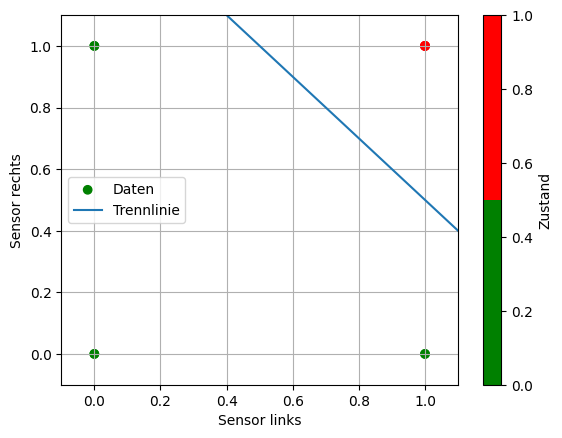

In [ ]:
#| code-fold: true
#| code-summary: "Lösung anzeigen"

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

sensorlinks = [0,1,1,1,0]
sensorrechts = [1,1,1,0,0]

karte = []
for i in range(len(sensorlinks)):
    karte.append(sensorlinks[i] + sensorrechts[i])

colors = ['green','green','red']
cmap = ListedColormap(colors)

plt.scatter(sensorlinks, sensorrechts, c = karte, cmap = cmap, label = 'Daten')
plt.xlabel('Sensor links')
plt.ylabel('Sensor rechts')
plt.grid()

# Farblegende hinzufügen
karte = []
for i in range(len(sensorlinks)):
    karte.append(1 if sensorlinks[i] and sensorrechts[i] else 0)
cmap = ListedColormap(['green', 'red'])
sc = plt.scatter(sensorlinks, sensorrechts, c=karte, cmap=cmap)
plt.colorbar(sc, label='Zustand')

xwerte = np.linspace(-1.1,1.1,100)
ywerte = 1.5 - xwerte*1
plt.plot(xwerte, ywerte, label='Trennlinie')
plt.xlim([-0.1,1.1])
plt.ylim([-0.1,1.1])
plt.legend()
plt.savefig('Bilder/roboter.png', dpi = 300)

### Beispiel 2:

Die Feuchtigkeit der Erde einer Basilikumpflanze wird durch 3 Messstellen überprüft. Zeigen 2 oder mehr Messungen (2 von 3 Auswahl) einen kritischen Wert an, muss bewässert werden. 

In [ ]:
#| code-fold: true
#| code-summary: "Lösung anzeigen"

# Mathematik
import numpy as np
# Plot
import matplotlib.pyplot as plt
# 4-dimensionaler Input = Bias-Neuron, messung1, messung2, messung3
# 8 Inputvektoren
X = np.array([[1,0,0,0],
              [1,0,0,1],
              [1,0,1,0],
              [1,0,1,1],
              [1,1,0,0],
              [1,1,0,1],
              [1,1,1,0],
              [1,1,1,1]])
# Die 4 gewünschten Ergebniswerte
y = np.array([0,0,0,1,0,1,1,1])

# Heaviside-Funktion
def heaviside( summe ):
    """Berechnung der Entscheidung zum Wert summe
    Input: summe
    Output: 1, falls summe >= 0,
    0 sonst
    """
    if summe >= 0:
        return 1
    else:
        return 0
    
# Perceptron-Berechnungc (Forward Path)
def perceptron_eval(X,y):
    """ Perceptron-Berechnung
    Input: X, Inputvektor
    y, der gewünschte Output
    Output: Der Gesamtfehler, d. h. Summe aus dem Betrag der Differenz
    von errechnetem und gewünschtem Output
    """
    # Der Gesamtfehler
    gesamtfehler = 0;
    # Die Gewichte so wählen, dass das Roboter-Problem gelöst werden kann
    w = np.array([-2,1,1,1])
    # Index i und Element x Ermittlung vom Array X
    for i, x in enumerate(X):
        # x = Zeile für Zeile verwenden
        # Inneres Produkt zwischen x und w
        summe = np.dot(w,x)
    ergebnis = heaviside(summe)
    # Fehler
    fehler = np.abs(ergebnis - y[i])
    # Gesamtfehler
    gesamtfehler += fehler
    # Ausgabe
    print("Messung 1 = {}, Messung 2 = {}, Messung 3 = {}, gewünschtes Ergebnis ={}, errechnetes Ergebnis = {}, Fehler = {}".format(x[1], x[2], x[3], y[i], ergebnis, fehler))
    # Gesamtfehler pro Epoche über ganzen Trainingsdatensatz
    return gesamtfehler
#------------------------------
# Core Function zum Auswerten des Inputs
gesamtfehler = perceptron_eval(X,y)
print("Gesamtfehler = %1d" % (gesamtfehler))

Messung 1 = 1, Messung 2 = 1, Messung 3 = 1, gewünschtes Ergebnis =1, errechnetes Ergebnis = 1, Fehler = 0
Gesamtfehler = 0


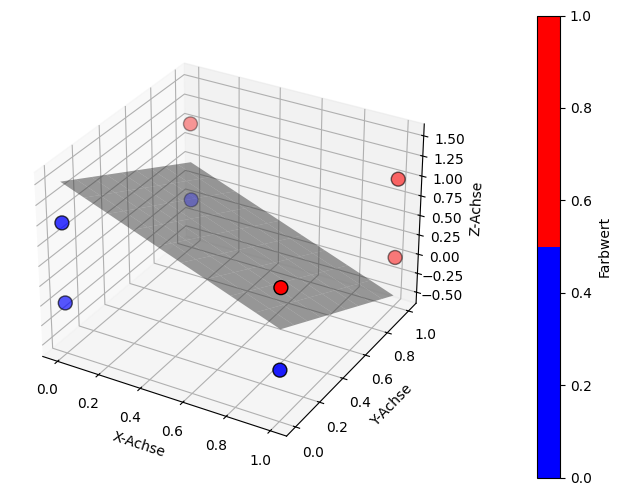

In [ ]:
#| code-fold: true
#| code-summary: "Lösung anzeigen"

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap

# Werte für die Achsen
x = np.array([0,0,0,0,1,1,1,1])
y = np.array([0,0,1,1,0,0,1,1])
z = np.array([0,1,0,1,0,1,0,1])

# Farben für die Punkte
c = np.array([0,0,0,1,0,1,1,1])

# Erstelle eine 3D-Figur
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

colors = ['blue', 'red']
cmap = ListedColormap(colors)

# Scatter-Plot mit Farbzuweisung
sc = ax.scatter(x, y, z, c=c, cmap=cmap, s=100, edgecolors="k")

# Achsentitel setzen
ax.set_xlabel("X-Achse")
ax.set_ylabel("Y-Achse")
ax.set_zlabel("Z-Achse")

# Farblegende hinzufügen
plt.colorbar(sc, ax=ax, pad=0.15, label="Farbwert")

# Trennebene einfügen
xx, yy = np.meshgrid(np.linspace(0, 1, 10), np.linspace(0, 1, 10))
zz = 2 - 0.5 * np.ones_like(xx)- xx - yy  # Eine horizontale Trennebene bei z=0.5

ax.plot_surface(xx, yy, zz, color='gray', alpha=0.5)  # Halbtransparente Trennebene

plt.savefig('Bilder/messungen.png', dpi = 300)

### Aufgabe 1 Einfaches Perzeptron programmieren
